In [2]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde
import csv
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from time import perf_counter
from matplotlib.patches import Circle, FancyArrowPatch
from skimage import morphology, measure
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 25
})

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.thickness import bell
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [3]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625





measuring 10 snapshots on 10 workers ...
  t=210: 230 sheets
  t=245: 196 sheets
  t=220: 206 sheets
  t=225: 211 sheets
  t=230: 210 sheets
  t=240: 213 sheets
  t=235: 204 sheets
  t=215: 228 sheets
  t=205: 236 sheets
  t=200: 240 sheets

saved thickness_vs_intensity_beta1.csv  (2174 sheets)
2174 sheets with both a thickness and an intensity


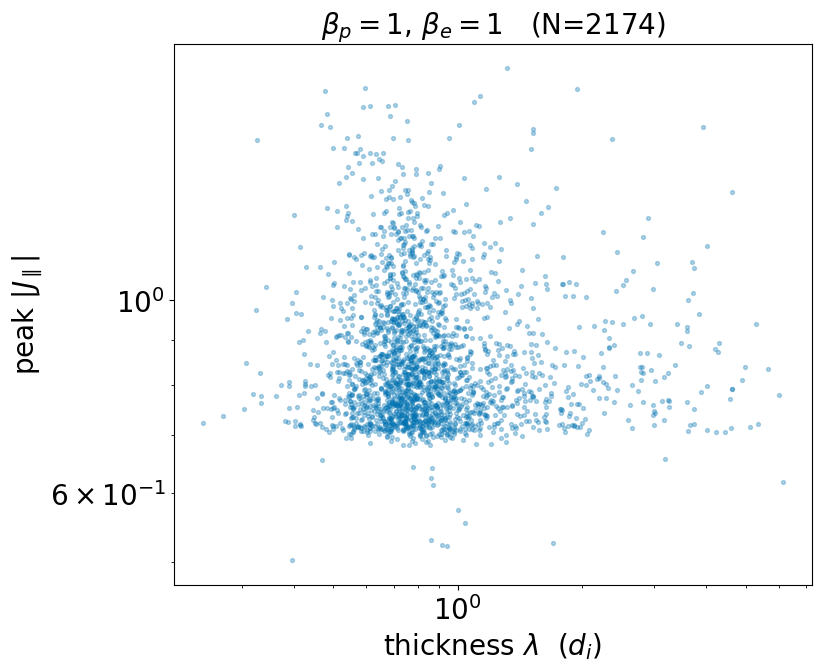

saved thickness_vs_intensity_beta1.png

thickness : median 0.790 d_i
intensity : median 0.8218  (peak |J_parallel|)


In [5]:
# =====================================================================
#  Current-sheet thickness (M3) versus intensity |J_parallel|
# ---------------------------------------------------------------------
#  One point per sheet. Both numbers come from the same bell-curve fit to the
#  |J| profile across the sheet, so they refer to the same measurement:
#
#      thickness = 2 sqrt(2 ln 2) * sigma       (the FWHM)
#      intensity = peak |J_parallel| in the sheet
#
#  Must already exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({"font.size": 16})

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA      = 1
TIMES     = list(range(200, 250, 5))
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)
cache_dir = str(CACHE / "filtered_cache_Jz")
out_fig   = str(RESULTS / f"thickness_vs_intensity_beta{BETA}.png")
out_csv   = str(RESULTS / f"thickness_vs_intensity_beta{BETA}.csv")

PX_PER_DI    = 16.0
CONNECTIVITY = 2
dx = dy      = 0.0625

SMOOTH_SIGMA = 3
MAX_LEN, SUBPIX_STEP, MARGIN_FRAC, MIN_HALF = 60, 0.5, 0.5, 6.0
MAX_FWHM_PX  = 100

N_WORKERS = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1
FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def _init_worker(n):
    if threadpool_limits is not None:
        threadpool_limits(limits=n)




def fit_profile(J2, mask, xm, ym, ux, uy):
    """Fit a bell curve to |J| along the line through (xm, ym).
    Returns (FWHM in px, amplitude A, background B), or NaNs if the fit fails."""
    nx, ny = mask.shape

    def edge(sx, sy):
        d = 0.0
        while d < MAX_LEN:
            dn = d + SUBPIX_STEP
            xi, yi = int(round(xm + sx * dn)) % nx, int(round(ym + sy * dn)) % ny
            if not mask[xi, yi]:
                break
            d = dn
        return d

    hf = min(MAX_LEN, max(MIN_HALF, edge(ux, uy) * (1 + MARGIN_FRAC)))
    hb = min(MAX_LEN, max(MIN_HALF, edge(-ux, -uy) * (1 + MARGIN_FRAC)))
    t = np.arange(-hb, hf + SUBPIX_STEP, SUBPIX_STEP)
    prof = ndi.map_coordinates(J2, np.vstack([xm + t * ux, ym + t * uy]),
                               order=1, mode="grid-wrap")
    if len(prof) < 4:
        return np.nan, np.nan, np.nan
    B0, A0 = float(prof.min()), float(prof.max() - prof.min())
    if A0 <= 0:
        return np.nan, np.nan, np.nan
    mu0 = float(t[np.argmax(prof)])
    above = np.where(prof >= B0 + 0.5 * A0)[0]
    s0 = (max(1.0, (t[above[-1]] - t[above[0]]) / 2.3548)
          if above.size >= 2 else max(2.0, (hf + hb) / 6.0))
    span = float(t.max() - t.min())
    s0 = min(s0, 0.99 * span)
    try:
        popt, _ = curve_fit(bell, t, prof, p0=[A0, mu0, s0, B0],
                            bounds=([0.0, t.min() - 1, 1e-3, -np.inf],
                                    [np.inf, t.max() + 1, span, np.inf]),
                            maxfev=10000)
    except (RuntimeError, ValueError):
        return np.nan, np.nan, np.nan
    A, _, sig, B = popt
    w = 2 * np.sqrt(2 * np.log(2)) * abs(sig)
    if w > MAX_FWHM_PX:
        return np.nan, np.nan, np.nan
    return w, float(A), float(B)


# -----------------------------
# one snapshot -> one row per sheet
# -----------------------------
def extract(time):
    n_iter, Xi = FILTER_PARAMS[BETA]
    base = f"{base_root}/beta_p_{BETA}/beta_e_1/"
    with h5py.File(base + f"Bx_{sim_tag}_t{time}.h5", "r") as fx, \
         h5py.File(base + f"By_{sim_tag}_t{time}.h5", "r") as fy, \
         h5py.File(base + f"Bz_{sim_tag}_t{time}.h5", "r") as fz:
        Bx, By, Bz = fx["DS1"][:].T, fy["DS1"][:].T, fz["DS1"][:].T

    cached = f"{cache_dir}/filtered_beta_{BETA}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cached):
        d = np.load(cached)
        Bxf, Byf, Bzf = d["Bx"], d["By"], d["Bz"]
    else:
        Bxf, Byf, Bzf = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cached, Bx=Bxf, By=Byf, Bz=Bzf)

    J2 = np.abs(partial_x_fft(Byf, dy) - partial_y_fft(Bxf, dx))

    mask = np.zeros_like(J2)
    for sheet in detect_current_sheets(J2):
        for (i, j) in sheet:
            mask[i, j] = 1
    disk = morphology.disk(1)
    mask = morphology.binary_opening(mask, disk)
    mask = morphology.binary_closing(mask, disk)
    cleaned = morphology.remove_small_objects(mask.astype(bool), min_size=500)
    labeled = measure.label(cleaned, connectivity=CONNECTIVITY)

    J2s = gaussian_filter(J2, sigma=SMOOTH_SIGMA)
    gx, gy = np.gradient(J2s)

    rows = []
    for k in range(1, int(labeled.max()) + 1):
        region = (labeled == k)
        vals = J2[region]
        xs_r, ys_r = np.where(region)
        pk = int(np.argmax(vals))
        xm, ym = int(xs_r[pk]), int(ys_r[pk])

        g = np.array([gx[xm, ym], gy[xm, ym]])
        if np.allclose(g, 0):
            continue
        v = -g / np.linalg.norm(g)
        w, A, B = fit_profile(J2, cleaned, xm, ym, float(v[0]), float(v[1]))
        if not np.isfinite(w) or w <= 0:
            continue
        rows.append([time, k, w / PX_PER_DI, A, B,
                     float(vals.max()), float(vals.mean()), int(region.sum())])
    return rows


COLUMNS = ["time", "sheet", "thickness_di", "fit_amplitude", "fit_background",
           "J_peak", "J_mean", "area_px"]


# =====================================================================
if __name__ == "__main__":
    all_rows = []
    print(f"measuring {len(TIMES)} snapshots on {N_WORKERS} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("fork"),
                             initializer=_init_worker,
                             initargs=(THREADS_PER_WORKER,)) as pool:
        jobs = {pool.submit(extract, t): t for t in TIMES}
        for job in as_completed(jobs):
            t = jobs[job]
            try:
                r = job.result(); all_rows += r
                print(f"  t={t}: {len(r)} sheets", flush=True)
            except FileNotFoundError:
                print(f"  t={t}: file missing, skipped", flush=True)

    if not all_rows:
        raise SystemExit("nothing measured -- check paths and TIMES")

    data = np.array(sorted(all_rows, key=lambda r: (r[0], r[1])), float)
    with open(out_csv, "w", newline="") as f:
        w_ = csv.writer(f); w_.writerow(COLUMNS); w_.writerows(data.tolist())
    print(f"\nsaved {out_csv}  ({len(data)} sheets)")

    lam   = data[:, 2]
    Jpeak = data[:, 5]
    ok = np.isfinite(lam) & (lam > 0) & np.isfinite(Jpeak) & (Jpeak > 0)
    lam, Jpeak = lam[ok], Jpeak[ok]
    print(f"{len(lam)} sheets with both a thickness and an intensity")

    fig, ax = plt.subplots(figsize=(8.5, 7))
    ax.scatter(lam, Jpeak, s=8, alpha=0.3, color="#0072B2")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"thickness $\lambda$  $(d_i)$")
    ax.set_ylabel(r"peak $|J_\parallel|$")
    ax.set_title(rf"$\beta_p={BETA}$, $\beta_e=1$   (N={len(lam)})")
    fig.tight_layout()
    fig.savefig(out_fig, dpi=250, bbox_inches="tight")
    plt.show()
    print(f"saved {out_fig}")

    # -------- numbers --------
    print(f"\nthickness : median {np.median(lam):.3f} d_i")
    print(f"intensity : median {np.median(Jpeak):.4f}  (peak |J_parallel|)")